# Can a bacterial gene's DNA sequence tell us whether it causes antibiotic resistance?

Derrick Kimutai Kibet-169651

Emmanuel Amor Ochieng- 169765

Karogo Joe Ndungu- 167141

Jesse Richard Owuor- 159287

Arkadie Ryan- 168052

## Stage 1: Research question and objectives

**Research question:** Can a bacterial gene's DNA sequence tell us whether it causes antibiotic resistance?

**Objectives**

1. Download antibiotic resistance gene sequences from CARD and a length-matched set of non-resistance bacterial genes from NCBI RefSeq, then clean them: check valid bases and lengths, remove duplicates, screen out hidden resistance genes with BLAST, and group near-identical sequences with CD-HIT.
2. Compare the two groups on sequence features (GC content and k-mer frequencies), and look for conserved regions within a major resistance gene family using multiple sequence alignment.
3. Interpret the results biologically by grouping resistance genes by drug class and resistance mechanism using CARD's annotations.
4. Build and evaluate classifiers (logistic regression and random forest) on k-mer features against two baselines (majority class and nearest BLAST hit), testing on gene families held out from training.

**Hypothesis**

- **H0:** Resistance and non-resistance genes do not differ in sequence features, and a sequence-based classifier performs no better than the majority-class baseline.
- **H1:** Resistance genes differ in sequence composition (GC content and k-mers), and a sequence-based classifier identifies them clearly better than the majority-class baseline.

## Stage 2: Data acquisition

Resistance genes come from CARD's protein homolog model (genes that cause resistance just by being present; we leave out the variant model, whose genes cause resistance only through specific mutations). Non-resistance candidates are all protein-coding genes from four NCBI RefSeq reference genomes: *E. coli*, *K. pneumoniae*, *S. aureus* and *P. aeruginosa*. We chose these four because they are common in CARD and are major causes of drug-resistant infections, so both groups come from the same kinds of bacteria.

In [33]:
# Installing packages and setting up the project folder
!pip -q install biopython

import os, re, json, time, tarfile, subprocess
import pandas as pd
from Bio import SeqIO, Entrez

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = '/content/drive/MyDrive/amr_project'
except Exception:
    print('Google Drive not connected, so the data is saved inside this Colab session instead.')
    PROJECT = '/content/amr_project'

DATA = f'{PROJECT}/data'
os.makedirs(DATA, exist_ok=True)
print('Data folder:', DATA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data folder: /content/drive/MyDrive/amr_project/data


In [3]:
# Downloading the CARD data
CARD_URL = 'https://card.mcmaster.ca/latest/data'
card_tar = f'{DATA}/card-data.tar.bz2'
card_dir = f'{DATA}/card'

if not os.path.exists(card_tar):
    subprocess.run(['wget', '-q', '-O', card_tar, CARD_URL], check=True)
if not os.path.exists(f'{card_dir}/aro_index.tsv'):
    os.makedirs(card_dir, exist_ok=True)
    with tarfile.open(card_tar, 'r:bz2') as t:
        t.extractall(card_dir)

with open(f'{card_dir}/card.json') as f:
    card_version = json.load(f).get('_version')
print('CARD version:', card_version)
print('Files in CARD download:', sorted(os.listdir(card_dir)))

CARD version: 4.0.2
Files in CARD download: ['CARD-Download-README.txt', 'PMID.tsv', 'aro_categories.tsv', 'aro_categories_index.tsv', 'aro_index.tsv', 'card.json', 'nucleotide_fasta_protein_homolog_model.fasta', 'nucleotide_fasta_protein_knockout_model.fasta', 'nucleotide_fasta_protein_overexpression_model.fasta', 'nucleotide_fasta_protein_variant_model.fasta', 'nucleotide_fasta_rRNA_gene_variant_model.fasta', 'protein_fasta_protein_homolog_model.fasta', 'protein_fasta_protein_knockout_model.fasta', 'protein_fasta_protein_overexpression_model.fasta', 'protein_fasta_protein_variant_model.fasta', 'shortname_antibiotics.tsv', 'shortname_pathogens.tsv', 'snps.txt']


In [4]:
# Loading the resistance genes and their annotations
card_fasta = f'{card_dir}/nucleotide_fasta_protein_homolog_model.fasta'

rows = []
for i, rec in enumerate(SeqIO.parse(card_fasta, 'fasta')):
    aro = re.search(r'ARO:(\d+)', rec.description)
    species = re.search(r'\[(.+?)\]\s*$', rec.description)
    rows.append({
        'seq_id': f'card_{i}',
        'original_header': rec.description,
        'aro': 'ARO:' + aro.group(1) if aro else None,
        'species': species.group(1) if species else None,
        'sequence': str(rec.seq).upper(),
    })
card_seqs = pd.DataFrame(rows)

aro_index = pd.read_csv(f'{card_dir}/aro_index.tsv', sep='\t')
annotations = (aro_index
               .drop_duplicates('ARO Accession')
               [['ARO Accession', 'ARO Name', 'AMR Gene Family', 'Drug Class', 'Resistance Mechanism']]
               .rename(columns={'ARO Accession': 'aro', 'ARO Name': 'aro_name',
                                'AMR Gene Family': 'gene_family', 'Drug Class': 'drug_class',
                                'Resistance Mechanism': 'mechanism'}))

card_df = card_seqs.merge(annotations, on='aro', how='left')
card_df['label'] = 1
card_df['source'] = 'CARD'

print('CARD resistance genes:', len(card_df))
print('Genes without a matching annotation:', card_df['gene_family'].isna().sum())
card_df[['seq_id', 'aro_name', 'gene_family', 'drug_class', 'mechanism', 'species']].head()

CARD resistance genes: 6059
Genes without a matching annotation: 0


,seq_id,aro_name,gene_family,drug_class,mechanism,species
0,card_0,CblA-1,CblA beta-lactamase,cephalosporin,antibiotic inactivation,mixed culture bacterium AX_gF3SD01_15
1,card_1,SHV-52,SHV beta-lactamase,cephalosporin;penicillin beta-lactam,antibiotic inactivation,Klebsiella pneumoniae
2,card_2,dfrF,trimethoprim resistant dihydrofolate reductase...,diaminopyrimidine antibiotic,antibiotic target replacement,Enterococcus faecalis
3,card_3,CTX-M-130,CTX-M beta-lactamase,azole antibiotic;cephalosporin;imidazole antib...,antibiotic inactivation,Escherichia coli
4,card_4,NDM-6,NDM beta-lactamase,carbapenem;cephalosporin;penicillin beta-lactam,antibiotic inactivation,Escherichia coli


In [5]:
# Downloading genes from the four RefSeq genomes
Entrez.email = 'joe.karogo@strathmore.edu'

GENOMES = {
    'Escherichia coli K-12 MG1655': 'NC_000913.3',
    'Klebsiella pneumoniae HS11286': 'NC_016845.1',
    'Staphylococcus aureus NCTC 8325': 'NC_007795.1',
    'Pseudomonas aeruginosa PAO1': 'NC_002516.2',
}

for name, acc in GENOMES.items():
    path = f'{DATA}/refseq_{acc}_cds.fasta'
    if not os.path.exists(path):
        handle = Entrez.efetch(db='nuccore', id=acc, rettype='fasta_cds_na', retmode='text')
        with open(path, 'w') as out:
            out.write(handle.read())
        handle.close()
        time.sleep(1)
    print(f'{name} ({acc}): {os.path.getsize(path) / 1e6:.1f} MB')

Escherichia coli K-12 MG1655 (NC_000913.3): 5.1 MB
Klebsiella pneumoniae HS11286 (NC_016845.1): 5.9 MB
Staphylococcus aureus NCTC 8325 (NC_007795.1): 2.9 MB
Pseudomonas aeruginosa PAO1 (NC_002516.2): 6.7 MB


In [6]:
# Loading the RefSeq genes
def tag(desc, key):
    m = re.search(rf'\[{key}=([^\]]+)\]', desc)
    return m.group(1) if m else None

rows = []
i = 0
for name, acc in GENOMES.items():
    for rec in SeqIO.parse(f'{DATA}/refseq_{acc}_cds.fasta', 'fasta'):
        rows.append({
            'seq_id': f'ref_{i}',
            'original_header': rec.description,
            'species': name,
            'gene': tag(rec.description, 'gene'),
            'protein': tag(rec.description, 'protein'),
            'pseudo': tag(rec.description, 'pseudo') == 'true',
            'sequence': str(rec.seq).upper(),
        })
        i += 1
ref_df = pd.DataFrame(rows)
ref_df['label'] = 0
ref_df['source'] = 'RefSeq'

print('RefSeq candidate genes:', len(ref_df))
ref_df.groupby('species').size()

RefSeq candidate genes: 17973


,0
species,
Escherichia coli K-12 MG1655,4318
Klebsiella pneumoniae HS11286,5316
Pseudomonas aeruginosa PAO1,5572
Staphylococcus aureus NCTC 8325,2767


In [7]:
# Combining both datasets into one table
raw_df = pd.concat([card_df, ref_df], ignore_index=True)
raw_df['length'] = raw_df['sequence'].str.len()
raw_df.to_csv(f'{DATA}/raw_sequences.csv', index=False)

print(raw_df['source'].value_counts())
print()
print('Most common species in CARD:')
print(card_df['species'].value_counts().head(10))

source
RefSeq    17973
CARD       6059
Name: count, dtype: int64

Most common species in CARD:
species
Pseudomonas aeruginosa                                                                          1054
Acinetobacter baumannii                                                                          728
Klebsiella pneumoniae                                                                            662
Escherichia coli                                                                                 548
Enterobacter cloacae                                                                             164
Bacteria, Viruses, Fungi, and other genome sequence associated with antimicrobial resistance     132
Citrobacter freundii                                                                             122
Acinetobacter pittii                                                                              93
Campylobacter jejuni                                                                     

### Description of files

| File | Source | What it contains |
| --- | --- | --- |
| `card-data.tar.bz2` | CARD | Compressed download of the latest CARD release |
| `nucleotide_fasta_protein_homolog_model.fasta` | CARD | DNA sequences of resistance genes that cause resistance by being present (protein homolog model) |
| `aro_index.tsv` | CARD | One row per CARD entry: ARO accession, gene name, AMR gene family, drug class and resistance mechanism |
| `card.json` | CARD | The full CARD database; used here only to record the version number |
| `refseq_<accession>_cds.fasta` (×4) | NCBI RefSeq | DNA sequences of every protein-coding gene in one reference genome |
| `raw_sequences.csv` | Created by us | Both sources combined into one table, before cleaning |

### Description of variables (`raw_df`)

| Variable | Type | Meaning |
| --- | --- | --- |
| `seq_id` | text | Our own short ID for each sequence (`card_…` or `ref_…`) |
| `original_header` | text | The full FASTA header from the source file |
| `label` | 0 / 1 | Target variable: 1 = resistance gene (CARD), 0 = non-resistance candidate (RefSeq) |
| `source` | text | Where the sequence came from: CARD or RefSeq |
| `species` | text | Bacterium the gene comes from |
| `aro` | text | CARD's Antibiotic Resistance Ontology accession (CARD only) |
| `aro_name` | text | Name of the resistance gene (CARD only) |
| `gene_family` | text | CARD's AMR gene family, e.g. TEM beta-lactamase (CARD only) |
| `drug_class` | text | Antibiotic class(es) the gene gives resistance to (CARD only) |
| `mechanism` | text | How the gene causes resistance, e.g. antibiotic inactivation (CARD only) |
| `gene` | text | Gene name from the genome annotation (RefSeq only) |
| `protein` | text | Protein product name (RefSeq only) |
| `pseudo` | True / False | Whether RefSeq marks the gene as a pseudogene (RefSeq only) |
| `sequence` | text | The DNA sequence (A, C, G, T) |
| `length` | number | Sequence length in base pairs |

### Stage 2 interpretation


We downloaded CARD version 4.0.2, which gave 6,059 resistance genes from the protein homolog model. Every one of them matched an entry in CARD's index, so each gene has a gene family, drug class and resistance mechanism, which we need for Stages 6 and 7.

From NCBI RefSeq we downloaded 17,973 protein-coding genes from the four reference genomes: 5,572 from *P. aeruginosa*, 5,316 from *K. pneumoniae*, 4,318 from *E. coli* and 2,767 from *S. aureus*. These are only candidates for now, because some may be resistance genes themselves, which we check with BLAST in Stage 3.

The most common species in CARD are *P. aeruginosa*, *Acinetobacter baumannii*, *K. pneumoniae* and *E. coli*, which supports our choice of genomes. However, *A. baumannii* is the second most common species in CARD but is not one of our four genomes, and some CARD entries have unclear sources such as "mixed culture bacterium". We also have about three times more RefSeq genes than CARD genes, so we balance the two groups in Stage 3.

Overall, the data can answer our question: we have expert-labelled resistance genes and a large pool of ordinary genes from the same kinds of bacteria.

## Stage 3: Preprocessing and quality control

We clean both sets in steps and count how many genes are left after each one: remove pseudogenes and invalid sequences, keep complete genes of a sensible length, remove exact duplicates, use BLAST to remove any RefSeq gene that looks like a known resistance gene, group near-identical genes with CD-HIT, and finally pick RefSeq genes with the same length distribution as the CARD genes.

In [8]:
# Installing BLAST and CD-HIT
!apt-get -qq install -y ncbi-blast+ cd-hit > /dev/null
!blastp -version | head -1
!cd-hit-est -h | head -1

blastp: 2.12.0+
		====== CD-HIT version 4.8.1 (built on Aug 20 2021) ======


In [9]:
# Basic quality checks
steps = []
def record(step, table):
    steps.append({'Step': step,
                  'CARD (resistant)': int((table['label'] == 1).sum()),
                  'RefSeq (non-resistant)': int((table['label'] == 0).sum())})

df = raw_df.copy()
record('Downloaded', df)

df = df[df['pseudo'] != True]
record('Removed pseudogenes', df)

df = df[df['sequence'].str.fullmatch(r'[ACGT]+')]
record('Removed sequences with letters other than A, C, G, T', df)

df = df[(df['length'] % 3 == 0) & (df['length'] >= 150) & (df['length'] <= 4000)]
record('Kept complete genes of 150 to 4,000 bp', df)

df = df.drop_duplicates('sequence')
record('Removed exact duplicate sequences', df)

pd.DataFrame(steps)

,Step,CARD (resistant),RefSeq (non-resistant)
0,Downloaded,6059,17973
1,Removed pseudogenes,6059,17955
2,"Removed sequences with letters other than A, C...",6044,17955
3,"Kept complete genes of 150 to 4,000 bp",6043,17299
4,Removed exact duplicate sequences,6043,17151


In [10]:
# Screening the RefSeq genes against CARD with BLAST
from Bio.Seq import Seq

work = '/content/work'
os.makedirs(work, exist_ok=True)

ref_part = df[df['label'] == 0]
with open(f'{work}/refseq_proteins.faa', 'w') as out:
    for sid, seq in zip(ref_part['seq_id'], ref_part['sequence']):
        protein = str(Seq(seq).translate(table=11, to_stop=True))
        if protein:
            out.write(f'>{sid}\n{protein}\n')

card_proteins = f'{card_dir}/protein_fasta_protein_homolog_model.fasta'
!makeblastdb -in "{card_proteins}" -dbtype prot -out {work}/card_prot > /dev/null
!blastp -query {work}/refseq_proteins.faa -db {work}/card_prot -evalue 1e-10 -max_target_seqs 1 -num_threads 4 -outfmt "6 qseqid sseqid pident length evalue bitscore qcovs" -out {work}/refseq_vs_card.tsv

hits = pd.read_csv(f'{work}/refseq_vs_card.tsv', sep='\t', header=None,
                   names=['seq_id', 'card_hit', 'pident', 'aln_len', 'evalue', 'bitscore', 'qcov'])
hits = hits.drop_duplicates('seq_id')
hidden = hits[(hits['pident'] >= 30) & (hits['qcov'] >= 50)]

df = df[~df['seq_id'].isin(hidden['seq_id'])]
record('Removed RefSeq genes that match a CARD gene (BLAST)', df)

print('RefSeq genes that look like resistance genes:', len(hidden))
hidden_named = hidden.merge(ref_df[['seq_id', 'species', 'protein']], on='seq_id')
print(hidden_named.groupby('species').size())
hidden_named[['species', 'protein', 'pident', 'qcov']].sort_values('pident', ascending=False).head(15)

RefSeq genes that look like resistance genes: 765
species
Escherichia coli K-12 MG1655       161
Klebsiella pneumoniae HS11286      259
Pseudomonas aeruginosa PAO1        259
Staphylococcus aureus NCTC 8325     86
dtype: int64


,species,protein,pident,qcov
762,Pseudomonas aeruginosa PAO1,beta-lactamase,100.000,100
345,Klebsiella pneumoniae HS11286,multidrug resistance outer membrane protein MdtQ,100.000,100
50,Escherichia coli K-12 MG1655,efflux pump MdtG,100.000,100
55,Escherichia coli K-12 MG1655,DNA-binding transcriptional dual regulator H-NS,100.000,100
114,Escherichia coli K-12 MG1655,outer membrane channel TolC,100.000,100
279,Klebsiella pneumoniae HS11286,beta-lactamase SHV-11,100.000,100
144,Escherichia coli K-12 MG1655,sensor histidine kinase CpxA,100.000,100
429,Staphylococcus aureus NCTC 8325,hypothetical protein,100.000,100
99,Escherichia coli K-12 MG1655,tripartite efflux pump membrane fusion protein...,100.000,91
98,Escherichia coli K-12 MG1655,tripartite efflux pump membrane subunit EmrY,100.000,100


In [11]:
# Grouping near-identical sequences with CD-HIT
def write_fasta(table, path):
    with open(path, 'w') as out:
        for sid, seq in zip(table['seq_id'], table['sequence']):
            out.write(f'>{sid}\n{seq}\n')

write_fasta(df[df['label'] == 1], f'{work}/card_clean.fna')
write_fasta(df[df['label'] == 0], f'{work}/ref_clean.fna')

!cd-hit-est -i {work}/card_clean.fna -o {work}/card_nr.fna -c 0.9 -n 8 -M 0 -T 0 -d 0 > /dev/null
!cd-hit-est -i {work}/ref_clean.fna -o {work}/ref_nr.fna -c 0.9 -n 8 -M 0 -T 0 -d 0 > /dev/null

keep = {rec.id for name in ['card_nr.fna', 'ref_nr.fna'] for rec in SeqIO.parse(f'{work}/{name}', 'fasta')}
df = df[df['seq_id'].isin(keep)]
record('Kept one gene per group of 90% identical genes (CD-HIT)', df)
print('Genes left after CD-HIT:')
print(df['source'].value_counts())

Genes left after CD-HIT:
source
RefSeq    16187
CARD       1314
Name: count, dtype: int64


In [12]:
# Matching the non-resistance genes to the resistance genes by length
card_part = df[df['label'] == 1]
ref_part = df[df['label'] == 0]

bins = list(range(150, 4001, 100)) + [4100]
card_bins = pd.cut(card_part['length'], bins, include_lowest=True)
ref_bins = pd.cut(ref_part['length'], bins, include_lowest=True)

picked = []
for length_bin, n in card_bins.value_counts().items():
    pool = ref_part[ref_bins == length_bin]
    picked.append(pool.sample(min(n, len(pool)), random_state=42))
ref_matched = pd.concat(picked)

clean_df = pd.concat([card_part, ref_matched], ignore_index=True)
record('Picked RefSeq genes with the same lengths as CARD genes', clean_df)
clean_df.to_csv(f'{DATA}/clean_sequences.csv', index=False)

In [13]:
# Before and after counts
summary = pd.DataFrame(steps)
display(summary)
print('Gene length (bp) in the final cleaned data:')
display(clean_df.groupby('source')['length'].describe().round(0))
print('Number of CARD gene families left:', clean_df['gene_family'].nunique())

,Step,CARD (resistant),RefSeq (non-resistant)
0,Downloaded,6059,17973
1,Removed pseudogenes,6059,17955
2,"Removed sequences with letters other than A, C...",6044,17955
3,"Kept complete genes of 150 to 4,000 bp",6043,17299
4,Removed exact duplicate sequences,6043,17151
5,Removed RefSeq genes that match a CARD gene (B...,6043,16386
6,Kept one gene per group of 90% identical genes...,1314,16187
7,Picked RefSeq genes with the same lengths as C...,1314,1307


Gene length (bp) in the final cleaned data:


,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
CARD,1314.0,1004.0,522.0,162.0,739.0,873.0,1164.0,3594.0
RefSeq,1307.0,989.0,502.0,168.0,717.0,870.0,1167.0,3639.0


Number of CARD gene families left: 387


### Stage 3 interpretation

Most basic checks removed very few genes: 18 RefSeq pseudogenes, 15 CARD genes with letters other than A, C, G and T, 657 genes that were incomplete or outside 150 to 4,000 bp, and 148 exact duplicates.

BLAST found 765 RefSeq genes that closely match CARD resistance genes (161 in *E. coli*, 259 in *K. pneumoniae*, 259 in *P. aeruginosa* and 86 in *S. aureus*). Many were 100% identical to CARD entries, including efflux pumps (MdtG, TolC, EmrY, RND pumps) and beta-lactamases such as SHV-11 in *K. pneumoniae*. These are natural resistance genes already in the bacteria's chromosomes, so without this step they would have been wrongly labelled as non-resistant. Some hits were less expected, such as general regulators (H-NS, CpxA) and "hypothetical proteins" in *S. aureus*, which shows that the line between resistance genes and ordinary genes is not always sharp.

CD-HIT had the biggest effect: the CARD set dropped from 6,043 to 1,314 genes, meaning almost four out of five CARD genes were near-copies (90% identical or more) of another gene. RefSeq barely changed (16,386 to 16,187). If we had kept the copies, the model could have looked far more accurate than it really is.

After length matching, the final dataset has 1,314 resistance genes and 1,307 non-resistance genes, from 387 CARD gene families. The two groups now have almost the same lengths (median 873 bp vs 870 bp), so length cannot explain any differences we find later.

## Stage 4: Exploratory data analysis

We describe the cleaned data with three plots: gene length, GC content, and a PCA of 4-mer frequencies (how often each 4-letter DNA "word" appears in a gene).

In [14]:
# Calculating GC content and 4-mer frequencies
import numpy as np
from itertools import product

K = 4
KMERS = [''.join(p) for p in product('ACGT', repeat=K)]
kmer_index = {k: i for i, k in enumerate(KMERS)}

def kmer_freqs(seq):
    counts = np.zeros(len(KMERS))
    for i in range(len(seq) - K + 1):
        counts[kmer_index[seq[i:i + K]]] += 1
    return counts / counts.sum()

clean_df['gc'] = clean_df['sequence'].apply(lambda s: (s.count('G') + s.count('C')) / len(s))
kmer_matrix = np.vstack([kmer_freqs(s) for s in clean_df['sequence']])
print('Feature table:', kmer_matrix.shape[0], 'genes x', kmer_matrix.shape[1], '4-mers')

Feature table: 2621 genes x 256 4-mers


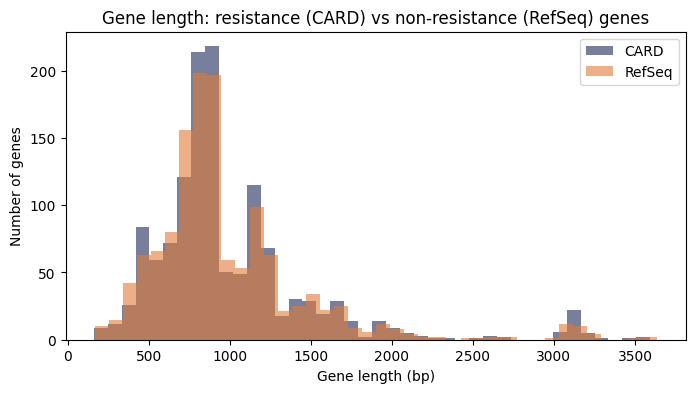

In [15]:
# Plot 1: gene length in both groups
import matplotlib.pyplot as plt

COLORS = {'CARD': '#1F2A5A', 'RefSeq': '#E07B39'}
fig, ax = plt.subplots(figsize=(8, 4))
for source, group in clean_df.groupby('source'):
    ax.hist(group['length'], bins=40, alpha=0.6, label=source, color=COLORS[source])
ax.set_xlabel('Gene length (bp)')
ax.set_ylabel('Number of genes')
ax.set_title('Gene length: resistance (CARD) vs non-resistance (RefSeq) genes')
ax.legend()
plt.show()

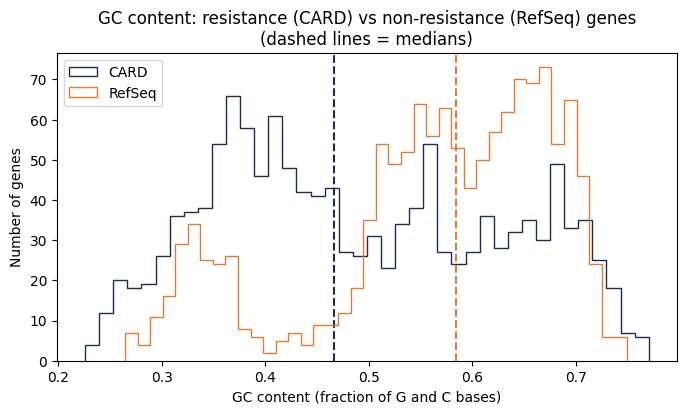

         count   mean    std    min    25%    50%    75%    max
source                                                         
CARD    1314.0  0.490  0.136  0.226  0.376  0.466  0.609  0.770
RefSeq  1307.0  0.565  0.116  0.265  0.516  0.584  0.655  0.749

GC content of the RefSeq genes by species:
species
Escherichia coli K-12 MG1655       0.525
Klebsiella pneumoniae HS11286      0.591
Pseudomonas aeruginosa PAO1        0.671
Staphylococcus aureus NCTC 8325    0.336
Name: gc, dtype: float64


In [16]:
# Plot 2: GC content in both groups
fig, ax = plt.subplots(figsize=(8, 4))
for source, group in clean_df.groupby('source'):
    ax.hist(group['gc'], bins=40, histtype='step', lw=2, label=source, color=COLORS[source])
    ax.axvline(group['gc'].median(), color=COLORS[source], ls='--', lw=1.5)
ax.set_xlabel('GC content (fraction of G and C bases)')
ax.set_ylabel('Number of genes')
ax.set_title('GC content: resistance (CARD) vs non-resistance (RefSeq) genes\n(dashed lines = medians)')
ax.legend()
plt.show()

print(clean_df.groupby('source')['gc'].describe().round(3))
print()
print('GC content of the RefSeq genes by species:')
print(clean_df[clean_df['label'] == 0].groupby('species')['gc'].median().round(3))

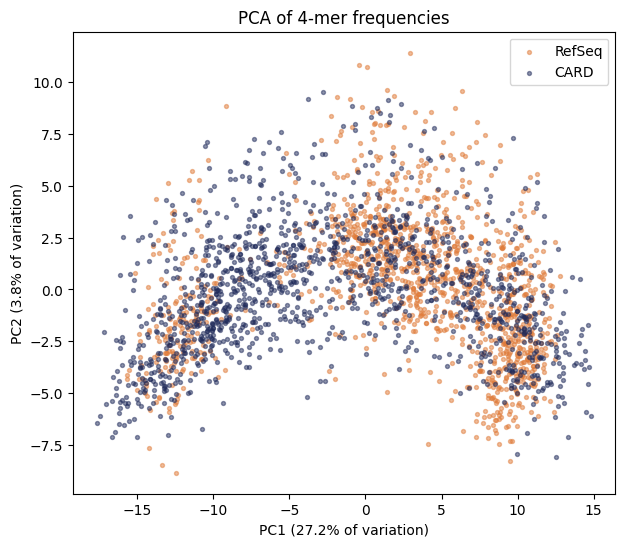

In [17]:
# Plot 3: PCA of 4-mer frequencies
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
coords = pca.fit_transform(StandardScaler().fit_transform(kmer_matrix))

fig, ax = plt.subplots(figsize=(7, 6))
for source in ['RefSeq', 'CARD']:
    mask = (clean_df['source'] == source).values
    ax.scatter(coords[mask, 0], coords[mask, 1], s=8, alpha=0.5, label=source, color=COLORS[source])
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} of variation)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} of variation)')
ax.set_title('PCA of 4-mer frequencies')
ax.legend()
plt.show()

### Stage 4 interpretation

The length plot shows that the resistance and non-resistance genes now have almost identical length distributions, which confirms that the matching in Stage 3 worked and that length cannot explain later differences.

The GC content plot shows a clear difference: resistance genes have a lower median GC content (0.466) than the non-resistance genes (0.584), and a wider spread. However, the non-resistance genes reflect their four genomes: three have high GC (*E. coli* 0.525, *K. pneumoniae* 0.591, *P. aeruginosa* 0.671) and one has low GC (*S. aureus* 0.336), which is why the RefSeq distribution has two peaks. Many resistance genes are carried on plasmids and move between species, keeping the GC content of the bacterium they came from, so part of this difference may come from the genes' origin rather than from resistance itself. We test this in Stage 5.

The PCA of 4-mer frequencies shows that the two groups overlap heavily, with no clean separation. The first component (27.2% of variation) mainly follows GC content, from low GC on the left to high GC on the right, and resistance genes spread further towards the low-GC side. This suggests that simple sequence composition does not easily separate the two groups, so any classifier will need more than these two dimensions.

## Stage 5: Core analysis

We test whether resistance and non-resistance genes differ in GC content and in each of the 256 4-mers, using Mann–Whitney U tests with FDR correction. We then check whether the GC difference holds within the same species, and align one major resistance gene family (CTX-M beta-lactamases) to find its conserved regions.

In [18]:
# Statistical tests on GC content and 4-mers
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

features = pd.DataFrame(kmer_matrix, columns=KMERS)
features.insert(0, 'GC content', clean_df['gc'].values)
is_card = (clean_df['label'] == 1).values

rows = []
for col in features.columns:
    a, b = features.loc[is_card, col], features.loc[~is_card, col]
    u, p = mannwhitneyu(a, b, alternative='two-sided')
    rows.append({'feature': col, 'median_CARD': a.median(), 'median_RefSeq': b.median(),
                 'effect_size': 2 * u / (len(a) * len(b)) - 1, 'p_value': p})
results = pd.DataFrame(rows)
results['q_value'] = multipletests(results['p_value'], method='fdr_bh')[1]
results['significant'] = results['q_value'] < 0.05

print('Features tested:', len(results))
print('Significant after FDR correction (q < 0.05):', results['significant'].sum())
print('Higher in resistance genes:', (results['significant'] & (results['effect_size'] > 0)).sum())
print('Lower in resistance genes:', (results['significant'] & (results['effect_size'] < 0)).sum())
display(results[results['feature'] == 'GC content'].round(4))
print('Top 15 features by effect size:')
results.reindex(results['effect_size'].abs().sort_values(ascending=False).index).head(15).round(4)

Features tested: 257
Significant after FDR correction (q < 0.05): 222
Higher in resistance genes: 120
Lower in resistance genes: 102


,feature,median_CARD,median_RefSeq,effect_size,p_value,q_value,significant
0,GC content,0.4663,0.5844,-0.3115,0.0,0.0,True


Top 15 features by effect size:


,feature,median_CARD,median_RefSeq,effect_size,p_value,q_value,significant
123,CTGG,0.0052,0.0116,-0.4750,0.0,0.0,True
251,TTGG,0.0046,0.0017,0.4487,0.0,0.0,True
159,GCTG,0.0061,0.0122,-0.4283,0.0,0.0,True
95,CCTG,0.0037,0.0080,-0.4114,0.0,0.0,True
122,CTGC,0.0043,0.0085,-0.4051,0.0,0.0,True
127,CTTG,0.0026,0.0012,0.4024,0.0,0.0,True
154,GCGC,0.0038,0.0117,-0.3993,0.0,0.0,True
167,GGCG,0.0049,0.0127,-0.3912,0.0,0.0,True
102,CGCC,0.0031,0.0108,-0.3856,0.0,0.0,True
83,CCAG,0.0027,0.0052,-0.3787,0.0,0.0,True


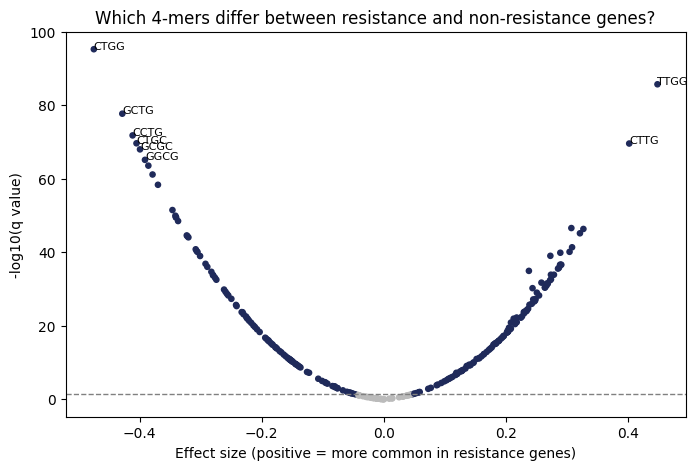

In [19]:
# Volcano plot of the 4-mer results
k = results[results['feature'] != 'GC content']
y = -np.log10(k['q_value'].clip(lower=1e-300))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(k['effect_size'], y, s=14, c=np.where(k['significant'], '#1F2A5A', '#BBBBBB'))
ax.axhline(-np.log10(0.05), ls='--', color='grey', lw=1)
for idx in k['effect_size'].abs().sort_values(ascending=False).index[:8]:
    ax.annotate(k.loc[idx, 'feature'], (k.loc[idx, 'effect_size'], y[idx]), fontsize=8)
ax.set_xlabel('Effect size (positive = more common in resistance genes)')
ax.set_ylabel('-log10(q value)')
ax.set_title('Which 4-mers differ between resistance and non-resistance genes?')
plt.show()

In [20]:
# Checking the GC difference within the same species
pairs = {
    'Escherichia coli': 'Escherichia coli K-12 MG1655',
    'Klebsiella pneumoniae': 'Klebsiella pneumoniae HS11286',
    'Pseudomonas aeruginosa': 'Pseudomonas aeruginosa PAO1',
    'Staphylococcus aureus': 'Staphylococcus aureus NCTC 8325',
}
rows = []
for card_sp, ref_sp in pairs.items():
    a = clean_df[(clean_df['label'] == 1) & (clean_df['species'] == card_sp)]['gc']
    b = clean_df[(clean_df['label'] == 0) & (clean_df['species'] == ref_sp)]['gc']
    p = mannwhitneyu(a, b).pvalue if len(a) >= 5 else np.nan
    rows.append({'species': card_sp, 'CARD genes': len(a), 'median GC (CARD)': a.median(),
                 'RefSeq genes': len(b), 'median GC (RefSeq)': b.median(), 'p_value': p})
pd.DataFrame(rows).round(4)

,species,CARD genes,median GC (CARD),RefSeq genes,median GC (RefSeq),p_value
0,Escherichia coli,58,0.4878,298,0.5251,0.1047
1,Klebsiella pneumoniae,27,0.5617,394,0.5910,0.0835
2,Pseudomonas aeruginosa,93,0.5497,437,0.6713,0.0000
3,Staphylococcus aureus,33,0.3171,178,0.3358,0.0115


In [21]:
# Aligning the CTX-M beta-lactamase family with MAFFT
!apt-get -qq install -y mafft > /dev/null
from Bio import AlignIO

FAMILY = 'CTX-M beta-lactamase'
family = card_df[card_df['gene_family'] == FAMILY]
with open(f'{work}/family.faa', 'w') as out:
    for sid, seq in zip(family['seq_id'], family['sequence']):
        out.write(f'>{sid}\n{Seq(seq).translate(table=11, to_stop=True)}\n')

!mafft --auto --quiet {work}/family.faa > {work}/family_aln.faa
aln = AlignIO.read(f'{work}/family_aln.faa', 'fasta')
print(FAMILY, ':', len(aln), 'protein sequences, alignment length', aln.get_alignment_length())

CTX-M beta-lactamase : 267 protein sequences, alignment length 313


Positions conserved in at least 95% of sequences: 203 of 313


,motif,sequence,alignment position,lowest conservation
0,S-x-x-K (active-site serine),STSK,84,0.996
3,K-T/S-G,KTG,254,0.974
2,S-D-N,SDN,144,0.970
1,S-x-x-K (active-site serine),SAAK,299,0.644


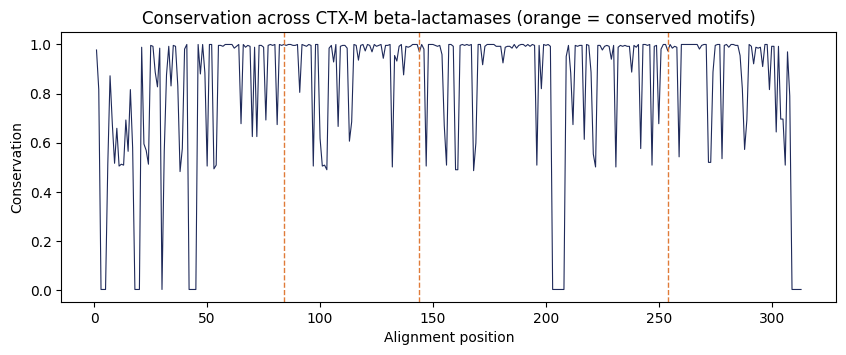

In [22]:
# Finding conserved positions and known beta-lactamase motifs
from collections import Counter

conservation, consensus = [], []
for i in range(aln.get_alignment_length()):
    column = [r for r in aln[:, i] if r != '-']
    if not column:
        conservation.append(0); consensus.append('-'); continue
    residue, count = Counter(column).most_common(1)[0]
    conservation.append(count / len(aln))
    consensus.append(residue)
consensus = ''.join(consensus)

motifs = {'S-x-x-K (active-site serine)': 'S..K', 'S-D-N': 'SDN', 'K-T/S-G': 'K[TS]G'}
found = []
for name, pattern in motifs.items():
    for m in re.finditer(pattern, consensus):
        found.append({'motif': name, 'sequence': m.group(), 'alignment position': m.start() + 1,
                      'lowest conservation': round(min(conservation[m.start():m.end()]), 3)})
motif_table = pd.DataFrame(found).sort_values('lowest conservation', ascending=False)
print('Positions conserved in at least 95% of sequences:', sum(c >= 0.95 for c in conservation), 'of', len(conservation))
display(motif_table)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(range(1, len(conservation) + 1), conservation, color='#1F2A5A', lw=0.8)
for pos in motif_table[motif_table['lowest conservation'] >= 0.95]['alignment position']:
    ax.axvline(pos, color='#E07B39', ls='--', lw=1)
ax.set_xlabel('Alignment position')
ax.set_ylabel('Conservation')
ax.set_title('Conservation across CTX-M beta-lactamases (orange = conserved motifs)')
plt.show()

### Stage 5 interpretation

Of the 257 features tested, 222 differed significantly between resistance and non-resistance genes after FDR correction (120 more common and 102 less common in resistance genes). GC content itself was clearly lower in resistance genes (median 0.466 vs 0.584, effect size −0.31, q < 0.001). The 4-mers with the largest differences tell the same story: those less common in resistance genes are almost all GC-rich (CTGG, GCTG, GCGC, CGCG), while those more common are AT-richer (TTGG, CTTG). With about 1,300 genes per group, even small differences become significant, so the effect sizes (up to about ±0.48) are a better guide than the p-values.

To check whether the GC difference only reflects the species mix, we compared resistance genes with genes from the same species. In all four species the resistance genes had lower GC than the host's own genes, but the difference was large and significant only in *P. aeruginosa* (0.550 vs 0.671, p < 0.001) and smaller in *S. aureus* (0.317 vs 0.336, p = 0.012), and it was not significant in *E. coli* (p = 0.10) or *K. pneumoniae* (p = 0.08). The species groups are small and these four tests are not corrected for multiple testing, so this is only a rough check. It suggests the GC difference is partly real and partly due to which species the genes come from.

The alignment of 267 CTX-M beta-lactamase proteins (taken from CARD before CD-HIT, since CD-HIT leaves too few family members to align) showed that 203 of 313 positions are conserved in at least 95% of sequences. It found the three known active-site motifs of class A beta-lactamases: STSK (99.6% conserved), SDN (97.0%) and KTG (97.4%). These form the part of the enzyme that breaks down beta-lactam antibiotics, which explains why they barely change. A fourth match, SAAK, was only 64.4% conserved and is a chance match rather than a real motif.

Overall, we can reject the first part of H0: resistance and non-resistance genes do differ in sequence composition, although part of this difference comes from species background.

## Stage 6: Biological interpretation

We use CARD's annotations to see which drug classes and resistance mechanisms our resistance genes cover, whether GC content differs by mechanism, and which kinds of resistance genes BLAST found hidden in the four genomes. We then compare our findings with published studies.

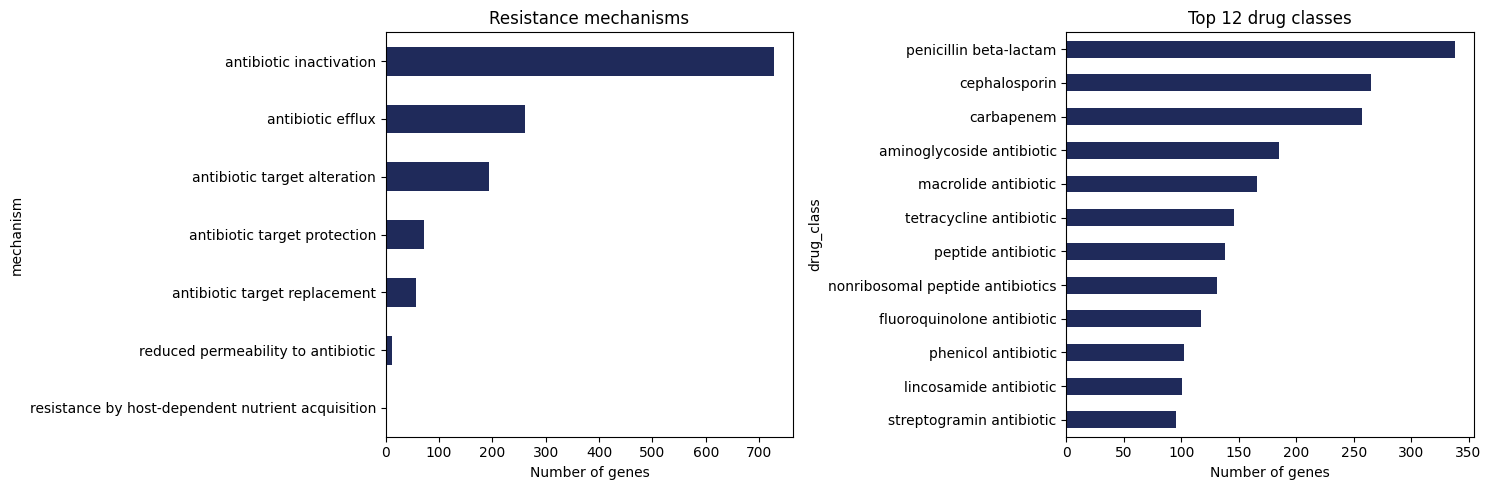

mechanism
antibiotic inactivation                              728
antibiotic efflux                                    261
antibiotic target alteration                         194
antibiotic target protection                          71
antibiotic target replacement                         57
reduced permeability to antibiotic                    12
resistance by host-dependent nutrient acquisition      1
Name: count, dtype: int64


In [23]:
# Resistance mechanisms and drug classes in our cleaned CARD genes
card_clean = clean_df[clean_df['label'] == 1]
mechanisms = card_clean['mechanism'].str.split(';').explode().value_counts()
drug_classes = card_clean['drug_class'].str.split(';').explode().value_counts().head(12)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
mechanisms.sort_values().plot.barh(ax=axes[0], color='#1F2A5A')
axes[0].set_title('Resistance mechanisms')
axes[0].set_xlabel('Number of genes')
drug_classes.sort_values().plot.barh(ax=axes[1], color='#1F2A5A')
axes[1].set_title('Top 12 drug classes')
axes[1].set_xlabel('Number of genes')
plt.tight_layout()
plt.show()
print(mechanisms)

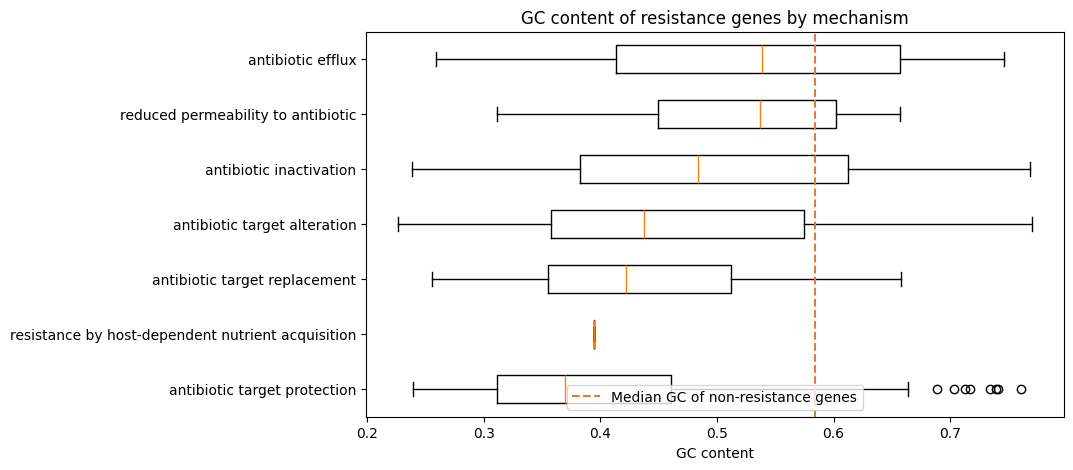

,count,median
mechanism,,
antibiotic target protection,71,0.370
resistance by host-dependent nutrient acquisition,1,0.394
antibiotic target replacement,57,0.422
antibiotic target alteration,194,0.437
antibiotic inactivation,728,0.484
reduced permeability to antibiotic,12,0.536
antibiotic efflux,261,0.539


In [24]:
# GC content by resistance mechanism
mech_gc = card_clean.assign(mechanism=card_clean['mechanism'].str.split(';')).explode('mechanism')
order = mech_gc.groupby('mechanism')['gc'].median().sort_values().index

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([mech_gc[mech_gc['mechanism'] == m]['gc'] for m in order], vert=False)
ax.set_yticklabels(order)
ax.axvline(clean_df[clean_df['label'] == 0]['gc'].median(), color='#E07B39', ls='--',
           label='Median GC of non-resistance genes')
ax.set_xlabel('GC content')
ax.set_title('GC content of resistance genes by mechanism')
ax.legend()
plt.show()
mech_gc.groupby('mechanism')['gc'].agg(['count', 'median']).round(3).sort_values('median')

In [25]:
# What kinds of resistance genes were hidden in the four genomes?
acc_to_aro = {}
for rec in SeqIO.parse(card_proteins, 'fasta'):
    parts = rec.description.split('|')
    aro = re.search(r'ARO:(\d+)', rec.description)
    if len(parts) > 1 and aro:
        acc_to_aro[parts[1]] = 'ARO:' + aro.group(1)

def hit_to_aro(hit):
    m = re.search(r'ARO:(\d+)', hit)
    if m:
        return 'ARO:' + m.group(1)
    return next((acc_to_aro[p] for p in hit.split('|') if p in acc_to_aro), None)

hidden_named['aro'] = hidden_named['card_hit'].apply(hit_to_aro)
hidden_mech = hidden_named.merge(annotations[['aro', 'mechanism']], on='aro', how='left')

comparison = pd.DataFrame({
    'Hidden in the 4 genomes (%)': hidden_mech['mechanism'].str.split(';').explode().value_counts(normalize=True) * 100,
    'CARD genes we used (%)': card_clean['mechanism'].str.split(';').explode().value_counts(normalize=True) * 100,
}).fillna(0).round(1).sort_values('Hidden in the 4 genomes (%)', ascending=False)
print('Hidden genes matched to a CARD entry:', hidden_mech['mechanism'].notna().sum(), 'of', len(hidden_mech))
comparison

Hidden genes matched to a CARD entry: 765 of 765


,Hidden in the 4 genomes (%),CARD genes we used (%)
mechanism,,
antibiotic efflux,74.0,19.7
antibiotic target alteration,13.7,14.7
reduced permeability to antibiotic,4.7,0.9
antibiotic inactivation,4.5,55.0
antibiotic target protection,1.9,5.4
antibiotic target replacement,1.1,4.3
resistance by host-dependent nutrient acquisition,0.0,0.1


### Stage 6 interpretation

Using CARD's annotations, most of our 1,314 resistance genes work by inactivating the antibiotic (728 genes, about 55%), followed by antibiotic efflux (261), target alteration (194), target protection (71) and target replacement (57). Beta-lactams dominate the drug classes (penicillins, cephalosporins and carbapenems), followed by aminoglycosides, macrolides and tetracyclines.

GC content differs clearly by mechanism. Target protection genes have the lowest GC (median 0.370), followed by target replacement (0.422) and target alteration (0.437), while efflux (0.539) and reduced permeability (0.536) genes are closest to the non-resistance genes (0.584). This matches what we found with BLAST in Stage 3: of the 765 resistance-like genes hidden in the four reference genomes, 74% were efflux pumps, compared with only 20% of our CARD genes, while antibiotic inactivation made up 55% of CARD genes but only 4.5% of the hidden ones. Efflux pumps and membrane permeability genes are mostly part of the bacteria's own chromosome (intrinsic resistance), so they share the host's GC content. Inactivating enzymes and target-protection genes are more often acquired from other bacteria on mobile elements such as plasmids, so they keep the lower GC content of the species they came from.

This agrees with Sánchez-Osuna, Barbé and Erill (2023), who showed that comparing the GC content of resistance genes with that of their host genome can reveal genes that have spread between species, and that this spread depends on the resistance mechanism. It also explains our Stage 5 result in *P. aeruginosa*, a high-GC species whose resistance genes have much lower GC than its own genes.

For our research question, this means part of the sequence "signal" of resistance genes is a signature of foreign origin rather than of resistance itself. We therefore expect a classifier to find acquired resistance genes (such as beta-lactamases) easier to recognise than intrinsic ones such as efflux pumps, which look like ordinary genes. An existing tool, DeepARG, developed by Arango-Argoty and colleagues in 2018, avoids this problem by learning similarity to known resistance genes rather than general sequence composition, which we test with our BLAST baseline in Stage 7.

## Stage 7: Machine learning

We train logistic regression and random forest models on the 256 4-mer frequencies and compare them with two baselines: always predicting the majority class, and predicting the label of each gene's nearest BLAST hit in the training data. We use 5-fold cross-validation where each CARD gene family is kept entirely in either the training or the test set, so the models are always tested on gene families they have never seen.

In [26]:
# Preparing features, labels and gene-family groups
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

X = kmer_matrix
y = clean_df['label'].values
groups = np.where(clean_df['label'] == 1, clean_df['gene_family'], clean_df['seq_id'])
proteins = [str(Seq(s).translate(table=11, to_stop=True)) or 'X' for s in clean_df['sequence']]
print('Genes:', len(y), '| resistance:', y.sum(), '| non-resistance:', (y == 0).sum())
print('CARD gene families:', clean_df.loc[y == 1, 'gene_family'].nunique())

Genes: 2621 | resistance: 1314 | non-resistance: 1307
CARD gene families: 387


In [27]:
# Training the models and baselines on unseen gene families
def scores(true, pred, prob):
    return {'accuracy': accuracy_score(true, pred),
            'balanced accuracy': balanced_accuracy_score(true, pred),
            'precision': precision_score(true, pred, zero_division=0),
            'recall (sensitivity)': recall_score(true, pred, zero_division=0),
            'F1': f1_score(true, pred, zero_division=0),
            'ROC AUC': roc_auc_score(true, prob) if prob is not None else np.nan}

def blast_predict(train_idx, test_idx):
    for name, idx in [('train', train_idx), ('test', test_idx)]:
        with open(f'{work}/{name}.faa', 'w') as out:
            for i in idx:
                out.write(f'>{i}\n{proteins[i]}\n')
    subprocess.run(['makeblastdb', '-in', f'{work}/train.faa', '-dbtype', 'prot', '-out', f'{work}/train_db'],
                   check=True, capture_output=True)
    subprocess.run(['blastp', '-query', f'{work}/test.faa', '-db', f'{work}/train_db', '-evalue', '1e-5',
                    '-max_target_seqs', '5', '-num_threads', '2', '-outfmt', '6 qseqid sseqid bitscore',
                    '-out', f'{work}/fold_hits.tsv'], check=True, capture_output=True)
    nearest = {}
    if os.path.getsize(f'{work}/fold_hits.tsv') > 0:
        hits = pd.read_csv(f'{work}/fold_hits.tsv', sep='\t', header=None, names=['q', 's', 'bits'])
        best = hits.sort_values('bits', ascending=False).drop_duplicates('q')
        nearest = dict(zip(best['q'], best['s']))
    return np.array([y[nearest[i]] if i in nearest else 0 for i in test_idx])

models = {
    'Majority class (baseline)': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'Random forest': RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42),
}

def evaluate(splits, include_blast=True):
    rows, oof = [], {}
    for fold, (tr, te) in enumerate(splits):
        for name, model in models.items():
            model.fit(X[tr], y[tr])
            pred, prob = model.predict(X[te]), model.predict_proba(X[te])[:, 1]
            oof.setdefault(name, np.zeros(len(y)))[te] = pred
            rows.append({'model': name, 'fold': fold, **scores(y[te], pred, prob)})
        if include_blast:
            pred = blast_predict(tr, te)
            oof.setdefault('Nearest BLAST hit (baseline)', np.zeros(len(y)))[te] = pred
            rows.append({'model': 'Nearest BLAST hit (baseline)', 'fold': fold, **scores(y[te], pred, None)})
    return pd.DataFrame(rows), oof

group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
grouped_scores, grouped_oof = evaluate(group_cv.split(X, y, groups))
results_table = grouped_scores.drop(columns='fold').groupby('model').agg(['mean', 'std']).round(3)
results_table

accuracy        balanced accuracy         \
                                 mean    std              mean    std   
model                                                                   
Logistic regression             0.804  0.025             0.806  0.024   
Majority class (baseline)       0.472  0.022             0.500  0.000   
Nearest BLAST hit (baseline)    0.779  0.059             0.781  0.052   
Random forest                   0.830  0.037             0.832  0.035   

                             precision        recall (sensitivity)         \
                                  mean    std                 mean    std   
model                                                                       
Logistic regression              0.829  0.048                0.772  0.093   
Majority class (baseline)        0.285  0.261                0.600  0.548   
Nearest BLAST hit (baseline)     0.949  0.021                0.592  0.101   
Random forest                    0.864  0.023                0.787  0.086   

                                 F1        ROC AUC         
                               mean    std    mean    std  
model                                                      
Logistic regression           0.795  0.040   0.873  0.041  
Majority class (baseline)     0.387  0.353   0.500  0.000  
Nearest BLAST hit (baseline)  0.726  0.079     NaN    NaN  
Random forest                 0.821  0.042   0.880  0.058

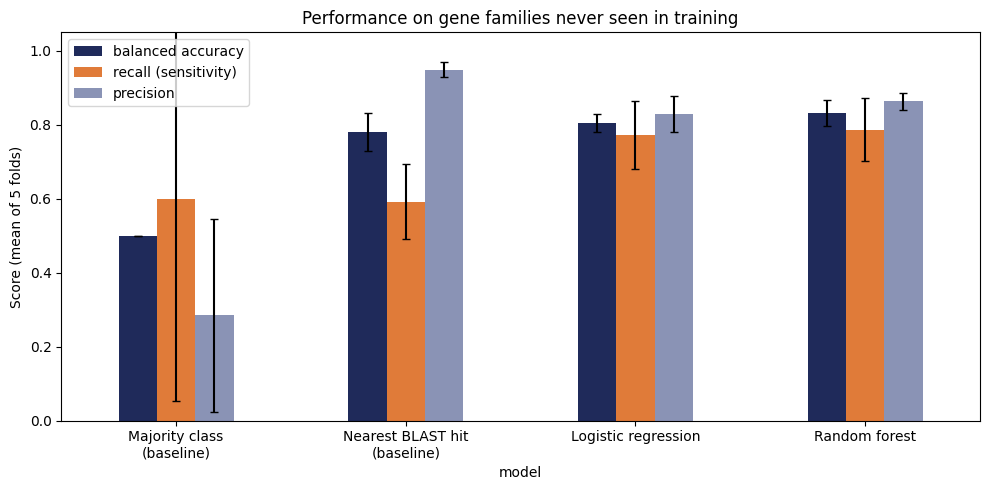

In [28]:
# Comparing the models with the baselines
order = ['Majority class (baseline)', 'Nearest BLAST hit (baseline)', 'Logistic regression', 'Random forest']
metrics = ['balanced accuracy', 'recall (sensitivity)', 'precision']
means = grouped_scores.groupby('model')[metrics].mean().loc[order]
stds = grouped_scores.groupby('model')[metrics].std().loc[order]

fig, ax = plt.subplots(figsize=(10, 5))
means.plot.bar(yerr=stds, ax=ax, color=['#1F2A5A', '#E07B39', '#8A93B5'], capsize=3, rot=0)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score (mean of 5 folds)')
ax.set_title('Performance on gene families never seen in training')
ax.set_xticklabels([o.replace(' (', '\n(') for o in order])
plt.tight_layout()
plt.show()

In [29]:
# How much does testing on unseen families matter? Comparison with a random split
random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
random_scores, _ = evaluate(random_cv.split(X, y), include_blast=False)
pd.DataFrame({
    'Random split': random_scores.groupby('model')['balanced accuracy'].mean(),
    'Unseen gene families': grouped_scores.groupby('model')['balanced accuracy'].mean(),
}).round(3)

,Random split,Unseen gene families
model,,
Logistic regression,0.825,0.806
Majority class (baseline),0.500,0.500
Nearest BLAST hit (baseline),NaN,0.781
Random forest,0.844,0.832


In [30]:
# Which kinds of resistance genes are easy or hard to detect?
is_res = y == 1
by_mech = clean_df.loc[is_res, ['mechanism']].copy()
by_mech['Random forest'] = grouped_oof['Random forest'][is_res]
by_mech['Nearest BLAST hit'] = grouped_oof['Nearest BLAST hit (baseline)'][is_res]
by_mech = by_mech.assign(mechanism=by_mech['mechanism'].str.split(';')).explode('mechanism')
(by_mech.groupby('mechanism')
        .agg(genes=('Random forest', 'size'),
             random_forest_recall=('Random forest', 'mean'),
             blast_recall=('Nearest BLAST hit', 'mean'))
        .round(3).sort_values('genes', ascending=False))

,genes,random_forest_recall,blast_recall
mechanism,,,
antibiotic inactivation,728,0.828,0.817
antibiotic efflux,261,0.475,0.341
antibiotic target alteration,194,0.902,0.258
antibiotic target protection,71,0.901,0.507
antibiotic target replacement,57,0.930,0.018
reduced permeability to antibiotic,12,0.417,0.250
resistance by host-dependent nutrient acquisition,1,1.000,0.000


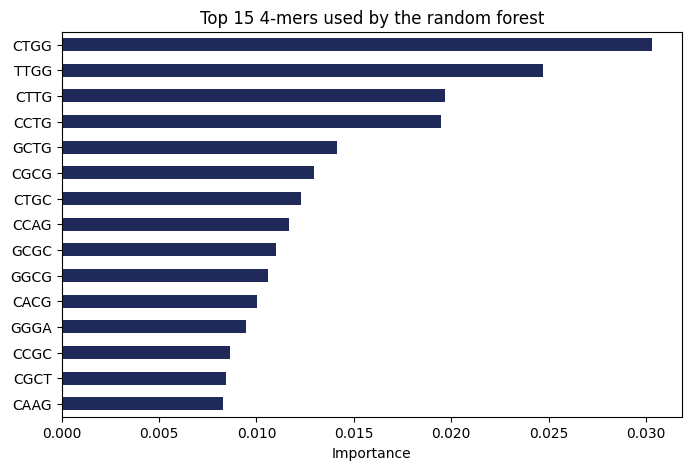

In [31]:
# The 4-mers the random forest relies on most
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42).fit(X, y)
importance = pd.Series(rf.feature_importances_, index=KMERS).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5))
importance.sort_values().plot.barh(ax=ax, color='#1F2A5A')
ax.set_xlabel('Importance')
ax.set_title('Top 15 4-mers used by the random forest')
plt.show()

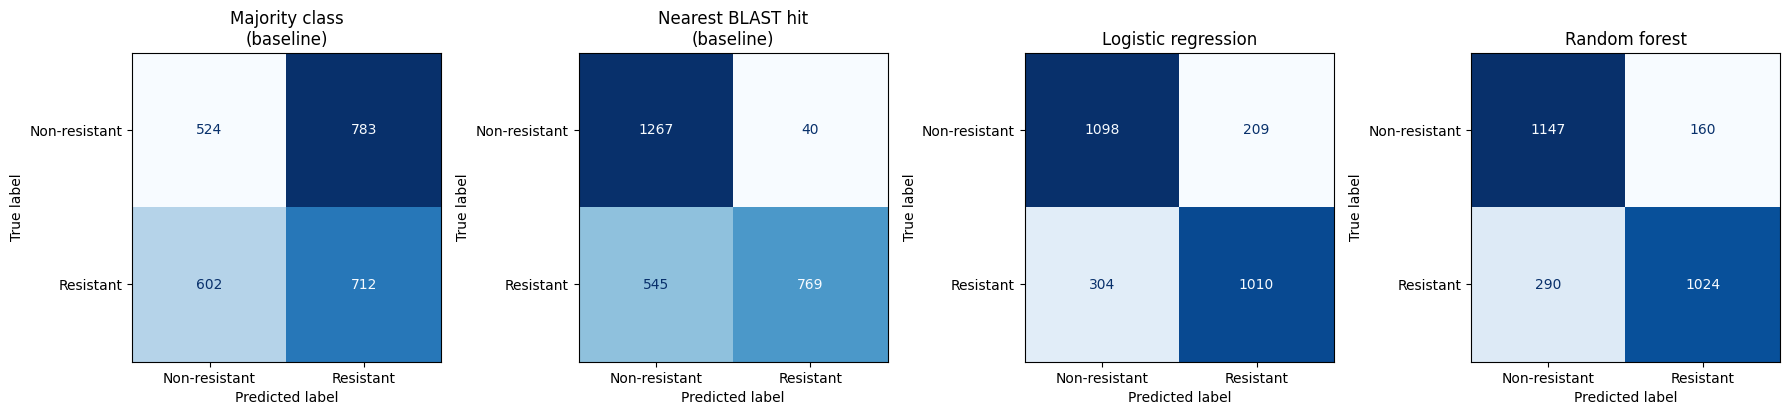

,true positives,false negatives,false positives,true negatives
model,,,,
Majority class (baseline),712,602,783,524
Nearest BLAST hit (baseline),769,545,40,1267
Logistic regression,1010,304,209,1098
Random forest,1024,290,160,1147


In [32]:
# Confusion matrices on unseen gene families
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

names = ['Majority class (baseline)', 'Nearest BLAST hit (baseline)', 'Logistic regression', 'Random forest']
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
rows = []
for ax, name in zip(axes, names):
    pred = grouped_oof[name].astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Non-resistant', 'Resistant']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name.replace(' (', '\n('))
    tn, fp, fn, tp = cm.ravel()
    rows.append({'model': name, 'true positives': tp, 'false negatives': fn,
                 'false positives': fp, 'true negatives': tn})
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index('model')

### Stage 7 interpretation

Tested on gene families they had never seen, both classifiers clearly beat the majority-class baseline (balanced accuracy 0.500). The random forest performed best (balanced accuracy 0.832 ± 0.035, recall 0.787, precision 0.864, ROC AUC 0.880), followed by logistic regression (0.806 ± 0.024). The majority-class baseline's large error bar for recall happens because in some folds the majority class was "resistant", so it predicted every gene as resistant.

The nearest-BLAST-hit baseline reached a balanced accuracy of 0.781. It had the highest precision (0.949), so when it called a gene resistant it was almost always right, but it found only 59% of resistance genes, because a gene from a new family often has no close relative in the training data. This is the main weakness of similarity-based tools: they only find genes similar to ones already known.

The confusion matrices show the exact errors on unseen gene families. The random forest correctly found 1,024 of the 1,314 resistance genes and missed 290 (false negatives), while wrongly flagging 160 of the 1,307 ordinary genes as resistant (false positives). The BLAST baseline made far fewer false positives (only 40) but missed 545 resistance genes, almost twice as many as the random forest. In a clinical setting a missed resistance gene is the more dangerous error, since it could lead to an antibiotic that does not work, which is why every prediction should be confirmed by laboratory testing.

Looking at each resistance mechanism, the random forest detected 83 to 93% of inactivation, target alteration, target protection and target replacement genes, but only 48% of efflux genes and 42% of reduced-permeability genes. This matches our Stage 6 prediction: efflux and permeability genes are mostly the bacteria's own chromosomal genes and look like ordinary genes. For target-replacement genes, the random forest found 93% while BLAST found only 2%, showing that sequence composition can catch resistance genes that have no known relatives.

However, the 4-mers the random forest relies on most (CTGG, TTGG, CTTG, CCTG) are the same GC-related 4-mers found in Stage 5. This suggests the model partly recognises the "foreign" composition of acquired genes rather than resistance itself, so it could wrongly flag other foreign genes, such as phage or plasmid genes that do not cause resistance.

Testing on unseen gene families gave only slightly lower scores than a random split (0.832 vs 0.844 for the random forest), because CD-HIT had already removed most near-identical copies in Stage 3.

## Stage 8: Conclusions

**Research question:** Can a bacterial gene's DNA sequence tell us whether it causes antibiotic resistance?

**Answer:** Partly. A random forest trained only on 4-mer frequencies identified resistance genes from gene families it had never seen with a balanced accuracy of 0.832, clearly better than the majority-class baseline (0.500) and also better than the nearest BLAST hit (0.781). We therefore reject H0. However, much of this signal reflects the foreign origin of acquired resistance genes rather than resistance itself.

**Objective 1 (data and cleaning):** We built a clean, balanced dataset of 1,314 CARD resistance genes and 1,307 length-matched RefSeq genes. BLAST removed 765 hidden resistance genes from the four genomes (74% of them efflux pumps), and CD-HIT showed that almost four out of five CARD genes were near-copies, which would otherwise have inflated our results.

**Objective 2 (sequence features and alignment):** Resistance genes had lower GC content than non-resistance genes (median 0.466 vs 0.584), and 222 of 257 features differed significantly after FDR correction. Within the same species the difference was smaller and significant only in *P. aeruginosa* and *S. aureus*, so part of it comes from species background. The CTX-M alignment found the three known class A beta-lactamase active-site motifs (STSK, SDN and KTG), each conserved in at least 97% of sequences.

**Objective 3 (biological interpretation):** GC content differed by resistance mechanism. Target-protection and target-replacement genes, which are often acquired from other bacteria, had the lowest GC, while efflux and permeability genes, which are mostly part of the bacteria's own chromosomes, were closest to ordinary genes.

**Objective 4 (machine learning):** Random forest (0.832) and logistic regression (0.806) both beat the two baselines on unseen gene families. The random forest found 83 to 93% of most resistance types but only 48% of efflux genes, while BLAST was very precise (0.949) but missed 41% of resistance genes.

**Limitations**

- Our non-resistance genes come from only four species, while CARD genes come from many, so species background affects our comparisons.
- Some non-resistance genes may still be undiscovered resistance genes.
- 4-mer frequencies capture overall composition, so the model may confuse other horizontally transferred genes with resistance genes.
- Our results come from curated reference sequences, not from real clinical samples, so they do not show how the model would perform in a hospital laboratory.

**Future steps**

- Add non-resistance genes from more species, including *A. baumannii*, to reduce species bias.
- Combine sequence composition with similarity search, since BLAST is precise and the random forest finds more.
- Test the model on genomes sequenced from Kenyan and other African clinical isolates.
- Add protein domain annotation (Pfam) and align more resistance gene families.

## References

1. Alcock, B. P. et al. (2023). CARD 2023: expanded curation, support for machine learning, and resistome prediction at the Comprehensive Antibiotic Resistance Database. *Nucleic Acids Research*, 51, D690–D699.
2. O'Leary, N. A. et al. (2016). Reference sequence (RefSeq) database at NCBI: current status, taxonomic expansion, and functional annotation. *Nucleic Acids Research*, 44, D733–D745.
3. Arango-Argoty, G. et al. (2018). DeepARG: a deep learning approach for predicting antibiotic resistance genes from metagenomic data. *Microbiome*, 6, 23.
4. Sánchez-Osuna, M., Barbé, J. & Erill, I. (2023). Systematic in silico assessment of antimicrobial resistance dissemination across the global plasmidome. *Antibiotics*, 12, 281.